Circular task analysis

In [10]:
# imports (this is all you need for this assignment - please, do not import anything else)
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle , Circle
import os
# very useful for plots that yo can zoom in-out
%matplotlib inline
# if the present working directory is the directory of this file, change the path to the project root
if os.getcwd().endswith("notebooks"):
    os.chdir("..")

In [11]:
data_file = "data/001MoDe_R1.csv"
marker_file = "data/001MoDe_R1.marker.csv"

with open(data_file) as f:
    first_line = f.readline().strip()
header = {}
for item in first_line.split(";"):
    name, value = item.split(" ", 1)
    header[name] = value
print(f"Header line information in '{data_file}':")
for name, value in header.items():
    print(f"  {name}: {value}")

cx, cy = float(header["centerX"]), float(header["centerY"])
Rt = float(header["taskRadius"])
tol = float(header["taskTolerance"])
W, H = float(header["screenWidth"]), float(header["screenHeight"])

with open(marker_file) as f:
    lines = f.read().splitlines()
markers = []
for line in lines[3:]:
    parts = line.split(",", 2)
    if len(parts) == 3 and parts[1].strip().isdigit():
        markers.append((int(parts[1]), parts[2]))
print(f"\nMarkers in '{marker_file}':")
for ts, text in markers:
    print(f"{ts}: {text}")

Header line information in 'data/001MoDe_R1.csv':
  screenWidth: 1104
  screenHeight: 661
  cornerX: 302
  cornerY: 80
  centerX: 552
  centerY: 330
  externalRadius: 250
  internalRadius: 170
  borderRadius: 1
  cursorRadius: 16
  indexOfDifficulty: 28.00696429476858
  taskRadius: 209.5
  taskTolerance: 47
  borderColor: java.awt.Color[r=255,g=255,b=255]
  backgroundColor: java.awt.Color[r=0,g=0,b=0]
  cursorColorRecord: java.awt.Color[r=255,g=0,b=0]
  cursorColorWait: java.awt.Color[r=255,g=255,b=0]
  autoStart: 3600
  cycleMaxNumber: 6
  cycleDuration: 20
  software: LSL-mouse
  version: 1.2.0rc5
  task: CircularTarget
  isWithLSL: false

Markers in 'data/001MoDe_R1.marker.csv':
1616776712325: KeyTyped=32 DoCycleChange
1616776712331: DoCycleChange:DoStartCycleTimedSequence
1616776712333: DoCycleChange:DoRecord RecordDone=0 PauseDone=0 ToDo=6
1616776732336: DoCycleChange:DoPause RecordDone=1 PauseDone=0 ToDo=6
1616776752340: DoCycleChange:DoRecord RecordDone=1 PauseDone=1 ToDo=6
1616

In [12]:
# data: timestamp (ms), mouseX, mouseY, mouseInTarget
d = np.loadtxt(data_file, delimiter=",", skiprows=4)
d = d[d[:, 0] > 0]
t0 = d[0, 0]                                   # time zero = first sample
ts = (d[:, 0] - t0) / 1000                     # time in seconds
x = d[:, 1] - cx                               # origin at the screen center
y = -(d[:, 2] - cy)                            # y axis pointing up
inside = d[:, 3]

# record start = DoRecord marker, record end = next DoPause marker
starts = [m[0] for m in markers if "DoRecord" in m[1]]
pauses = [m[0] for m in markers if "DoPause" in m[1]]
ends = pauses[:len(starts)]
ends += [int(d[-1, 0])] * (len(starts) - len(ends))

print("record times (seconds since the first sample):")
for s, e in zip(starts, ends):
    print(f"{(s - t0)/1000:7.3f} to {(e - t0)/1000:7.3f} ({(e - s)/1000:.3f} s)")

record times (seconds since the first sample):
  0.004 to  20.007 (20.003 s)
 40.011 to  60.022 (20.011 s)
 80.043 to 100.057 (20.014 s)
120.061 to 140.075 (20.014 s)
160.090 to 180.104 (20.014 s)


In [13]:
records = []
for s, e in zip(starts, ends):
    m = (d[:, 0] >= s) & (d[:, 0] <= e)
    records.append(dict(t=ts[m], x=x[m], y=y[m], inside=inside[m]))

print("Number of records:", len(records))
for i, r in enumerate(records):
    dur = r["t"][-1] - r["t"][0]
    print(f"record {i}: {len(r['t'])} samples from {r['t'][0]:7.3f} to {r['t'][-1]:7.3f} s, ({dur:.3f}s, {(len(r['t'])-1)/dur:.3f} Hz)")

Number of records: 5
record 0: 3971 samples from   0.022 to  20.004 s, (19.982s, 198.679 Hz)
record 1: 3898 samples from  40.429 to  60.018 s, (19.589s, 198.938 Hz)
record 2: 3898 samples from  80.371 to 100.050 s, (19.679s, 198.028 Hz)
record 3: 3884 samples from 120.608 to 140.069 s, (19.461s, 199.527 Hz)
record 4: 3936 samples from 160.146 to 180.098 s, (19.952s, 197.223 Hz)


Statistics table

In [14]:
def stats(r):
    # skip the approach phase: start at the first sample inside the target
    k = np.argmax(r["inside"] == 1)
    t, xx, yy, ins = r["t"][k:], r["x"][k:], r["y"][k:], r["inside"][k:]
    radius = np.hypot(xx, yy)
    angle = np.unwrap(np.arctan2(yy, xx))
    nLaps = (angle[-1] - angle[0]) / (2*np.pi)     
    Re = radius.mean()                             
    Te = 4.133 * radius.std()                     
    error = 100 * (1 - ins.mean())                 
    MT = (t[-1] - t[0]) / abs(nLaps)             
    IDe = 2*np.pi*Re / Te                         
    Be = Te / tol                                  
    IPe = IDe / MT                                  
    return [nLaps, Re, Te, error, MT, IDe, Be, IPe]

# theoretical error: normal distribution with Te = 4.133 sd -> tolerance = +-2.0665 sd
u = np.linspace(4.133/2, 10, 100000)
theory_error = 200 * np.sum(np.exp(-u**2/2) / np.sqrt(2*np.pi)) * (u[1] - u[0])

print("recomputed statistics for all records:")
print("   Var , nLaps ,      Re ,      Te ,   error ,  MT/lap , IDe/lap ,      Be ,     IPe ,")
print("  unit ,   lap ,   pixel ,   pixel ,       % ,   s/lap , bit/lap ,  double ,   bit/s ,")
print(f"Theory , {1:5.2f} , {Rt:7.2f} , {tol:7.2f} , {theory_error:7.2f} ,         ,         , {1:7.2f} ,         ,")
for i, r in enumerate(records):
    s = stats(r)
    print(f"Rec{i+1:03d} ," + " ,".join(f"{v:8.2f}" for v in s) + " ,")

recomputed statistics for all records:
   Var , nLaps ,      Re ,      Te ,   error ,  MT/lap , IDe/lap ,      Be ,     IPe ,
  unit ,   lap ,   pixel ,   pixel ,       % ,   s/lap , bit/lap ,  double ,   bit/s ,
Theory ,  1.00 ,  209.50 ,   47.00 ,    3.88 ,         ,         ,    1.00 ,         ,
Rec001 ,  -10.84 ,  213.86 ,   91.79 ,    5.39 ,    1.84 ,   14.64 ,    1.95 ,    7.94 ,
Rec002 ,  -11.97 ,  209.85 ,   34.45 ,    0.87 ,    1.59 ,   38.27 ,    0.73 ,   24.04 ,
Rec003 ,  -13.26 ,  209.43 ,   42.42 ,    2.89 ,    1.45 ,   31.02 ,    0.90 ,   21.40 ,
Rec004 ,  -12.83 ,  209.46 ,   37.14 ,    0.16 ,    1.49 ,   35.43 ,    0.79 ,   23.72 ,
Rec005 ,  -14.74 ,  210.89 ,   43.88 ,    2.63 ,    1.30 ,   30.20 ,    0.93 ,   23.20 ,


Raw plots

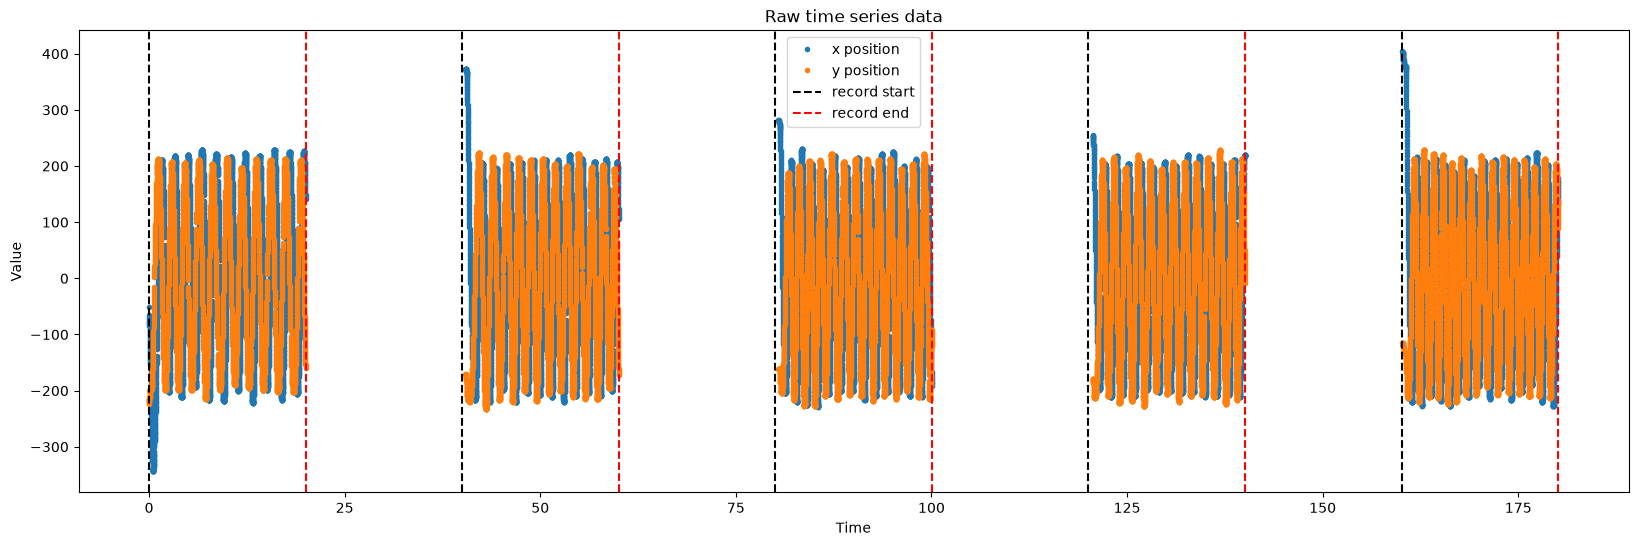

In [15]:
# raw time series
plt.figure(figsize=(20, 6))
plt.plot(ts, x, ".", label="x position")
plt.plot(ts, y, ".", label="y position")
for i, (s, e) in enumerate(zip(starts, ends)):
    plt.axvline((s - t0)/1000, color="k", ls="--", label="record start" if i == 0 else None)
    plt.axvline((e - t0)/1000, color="r", ls="--", label="record end" if i == 0 else None)
plt.title("Raw time series data")
plt.xlabel("Time"); plt.ylabel("Value")
plt.legend()
plt.show()